# Chapitre 3 - Exercices 3.26 à 3.30

| Exercice | Thème |
|---|---|
| 3.26 | Sélection ascendante et LAR : deux critères d'entrée différents |
| 3.27 | Conditions de Karush–Kuhn–Tucker du lasso, chemin linéaire par morceaux |
| 3.28 | Lasso avec une variable dupliquée |
| 3.29 | Ridge avec une variable dupliquée |
| 3.30 | L'elastic net comme un lasso sur des données augmentées |

Fonctions utilisées : `esl/ch03_regression_complements.py`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl import ch03_regression_complements as rc

set_style()
np.set_printoptions(precision=4, suppress=True)

Les données du cancer de la prostate (échantillon d'apprentissage, 67 patients, 8
prédicteurs centrés-réduits) serviront d'exemple réel dans les exercices 3.27 à 3.29.

In [2]:
pro = datasets.load_prostate()
pro_tr = pro[pro["train"]]
pnames = list(pro.columns[:8])
Xp, _, _, _ = rc.standardize(pro_tr[pnames].to_numpy(float))
yp = pro_tr["lpsa"].to_numpy(float)
yp = yp - yp.mean()
print(Xp.shape)

(67, 8)


## Exercice 3.26 : Sélection ascendante contre LAR

**Énoncé (reformulé).** La sélection pas à pas ascendante (*forward stepwise*) fait entrer
à chaque étape la variable qui diminue le plus la somme des carrés résiduelle (RSS). Le LAR
fait progresser la variable de plus forte corrélation absolue avec le résidu courant.
Montrer que ces deux critères d'entrée ne sont pas nécessairement les mêmes.
*Indication :* notons $\mathbf x_{j\cdot\mathcal A}$ la variable $\mathbf x_j$ ajustée
linéairement sur les variables déjà dans le modèle ; montrer que le premier critère revient à
chercher le $j$ maximisant $|\operatorname{Corr}(\mathbf x_{j\cdot\mathcal A},\mathbf r)|$.

### Notations

Variables et réponse sont centrées ; les $\mathbf x_j$ sont de norme 1. Le modèle courant
contient les variables $\mathcal A$ ; $\mathbf H_{\mathcal A}$ est la projection orthogonale sur
$\operatorname{Vect}(\mathbf x_k,k\in\mathcal A)$ et $\mathbf r=\mathbf y-\mathbf H_{\mathcal A}\mathbf y$
le résidu (orthogonal aux variables actives). La variable ajustée est
$\mathbf x_{j\cdot\mathcal A}=\mathbf x_j-\mathbf H_{\mathcal A}\mathbf x_j$, orthogonale à
$\operatorname{Vect}(\mathbf x_k, k\in\mathcal A)$.

### Gain en RSS de la sélection ascendante

Ajouter $\mathbf x_j$ revient à projeter $\mathbf y$ sur
$\operatorname{Vect}(\mathbf x_k,k\in\mathcal A)\oplus\operatorname{Vect}(\mathbf x_{j\cdot\mathcal A})$
(même espace que avec $\mathbf x_j$, et somme **orthogonale**). La projection sur une somme
orthogonale est la somme des projections :

$$
\hat{\mathbf y}_{\mathcal A\cup\{j\}}=\mathbf H_{\mathcal A}\mathbf y+\frac{\langle\mathbf x_{j\cdot\mathcal A},\mathbf y\rangle}{\|\mathbf x_{j\cdot\mathcal A}\|^2}\mathbf x_{j\cdot\mathcal A}.
$$

Par Pythagore, la RSS diminue de

$$
\Delta_j=\frac{\langle\mathbf x_{j\cdot\mathcal A},\mathbf y\rangle^2}{\|\mathbf x_{j\cdot\mathcal A}\|^2}
=\frac{\langle\mathbf x_{j\cdot\mathcal A},\mathbf r\rangle^2}{\|\mathbf x_{j\cdot\mathcal A}\|^2}
=\|\mathbf r\|^2\cos^2(\mathbf x_{j\cdot\mathcal A},\mathbf r)
=\|\mathbf r\|^2\operatorname{Corr}^2(\mathbf x_{j\cdot\mathcal A},\mathbf r),
$$

où l'on a utilisé $\langle\mathbf x_{j\cdot\mathcal A},\mathbf H_{\mathcal A}\mathbf y\rangle=0$, et
le fait que pour des vecteurs centrés la corrélation est le cosinus de l'angle. Maximiser
$\Delta_j$ revient bien à maximiser $|\operatorname{Corr}(\mathbf x_{j\cdot\mathcal A},\mathbf r)|$.

### Critère du LAR

Le LAR choisit le $j$ maximisant $|\langle\mathbf x_j,\mathbf r\rangle|$. Comme $\mathbf r$ est
orthogonal aux variables actives, $\langle\mathbf x_j,\mathbf r\rangle=\langle\mathbf x_{j\cdot\mathcal A},\mathbf r\rangle$. En résumé, à résidu donné :

$$
\text{ascendante : }\max_j\frac{|\langle\mathbf x_{j\cdot\mathcal A},\mathbf r\rangle|}{\|\mathbf x_{j\cdot\mathcal A}\|},
\qquad
\text{LAR : }\max_j|\langle\mathbf x_{j\cdot\mathcal A},\mathbf r\rangle| .
$$

Les deux critères diffèrent par le facteur $1/\|\mathbf x_{j\cdot\mathcal A}\|\ge1$, d'autant plus
grand que $\mathbf x_j$ est **corrélée aux variables déjà présentes**. La sélection ascendante
favorise donc ces variables (une fois « nettoyées », elles peuvent expliquer beaucoup de
résidu), alors que le LAR les ignore. Les deux critères coïncident lorsque toutes les
$\|\mathbf x_{j\cdot\mathcal A}\|$ sont égales (par exemple si les prédicteurs sont orthogonaux,
ou à la première étape où $\mathcal A=\varnothing$).

### Un contre-exemple explicite

Dans une base orthonormée $(\mathbf q_1,\dots,\mathbf q_4)$ de vecteurs centrés de
$\mathbb R^N$ : $\mathbf x_1=\mathbf q_1$ (déjà dans le modèle),
$\mathbf x_2=\cos\theta\,\mathbf q_1+\sin\theta\,\mathbf q_2$ avec $\sin\theta=0{,}4$ (très corrélée à
$\mathbf x_1$), $\mathbf x_3=\mathbf q_3$, et le résidu
$\mathbf r=0{,}75\,\mathbf q_2+0{,}5\,\mathbf q_3+0{,}2\,\mathbf q_4$. Alors
$\langle\mathbf x_2,\mathbf r\rangle=0{,}3<\langle\mathbf x_3,\mathbf r\rangle=0{,}5$ (le LAR choisit
$\mathbf x_3$), mais $\|\mathbf x_{2\cdot\mathcal A}\|=0{,}4$ donne $\Delta_2=0{,}3^2/0{,}16=0{,}5625>\Delta_3=0{,}25$
(la sélection ascendante choisit $\mathbf x_2$).

In [3]:
rng = np.random.RandomState(0)
N = 50
Qfull = np.linalg.qr(np.column_stack([np.ones(N), rng.randn(N, 4)]))[0]
q = Qfull[:, 1:]                                  # 4 vecteurs centrés orthonormés
sin_t = 0.4
x1, x2, x3 = q[:, 0], np.sqrt(1 - sin_t ** 2) * q[:, 0] + sin_t * q[:, 1], q[:, 2]
r = 0.75 * q[:, 1] + 0.5 * q[:, 2] + 0.2 * q[:, 3]
H = np.outer(x1, x1)                              # projection sur Vect(x1)
for name, x in [("x2", x2), ("x3", x3)]:
    xa = x - H @ x
    print(f"{name} : <x, r> = {x @ r:.3f}   ||x.A|| = {np.linalg.norm(xa):.3f}"
          f"   baisse de RSS = {(xa @ r) ** 2 / (xa @ xa):.4f}")

x2 : <x, r> = 0.300   ||x.A|| = 0.400   baisse de RSS = 0.5625
x3 : <x, r> = 0.500   ||x.A|| = 1.000   baisse de RSS = 0.2500


### Sur des données simulées : les ordres d'entrée diffèrent souvent

On compare l'ordre d'entrée des variables de la sélection ascendante et du LAR (chacun avec
son propre résidu) sur 300 jeux simulés à prédicteurs corrélés.

In [4]:
rng = np.random.RandomState(1)
p = 6
cov = 0.8 ** np.abs(np.subtract.outer(np.arange(p), np.arange(p)))
L = np.linalg.cholesky(cov)
first_diff = []
for _ in range(300):
    Xs = rng.randn(60, p) @ L.T
    ys = Xs @ rng.randn(p) + 2 * rng.randn(60)
    Xs, _, _, _ = rc.standardize(Xs, unit_norm=True)
    ys -= ys.mean()
    order_fs = rc.forward_stepwise(Xs, ys)[0]
    order_lar = [j for ev, j in rc.lars(Xs, ys)["events"] if ev == "entrée"]
    diff = [k for k in range(p) if order_fs[k] != order_lar[k]]
    first_diff.append(diff[0] + 1 if diff else 0)
first_diff = np.array(first_diff)
print("proportion de jeux où les ordres diffèrent :", np.mean(first_diff > 0))

proportion de jeux où les ordres diffèrent : 0.8933333333333333


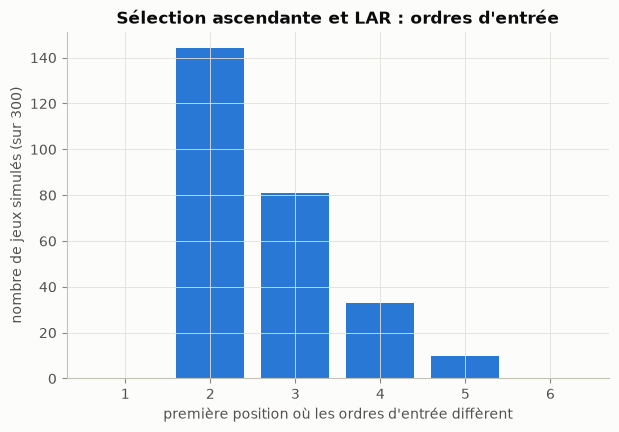

In [5]:
fig, ax = plt.subplots()
counts = [np.sum(first_diff == k) for k in range(1, p + 1)]
ax.bar(range(1, p + 1), counts, color=BLUE)
ax.set_xlabel("première position où les ordres d'entrée diffèrent")
ax.set_ylabel("nombre de jeux simulés (sur 300)")
ax.set_title("Sélection ascendante et LAR : ordres d'entrée")
plt.show()

Les ordres coïncident toujours à la première position (critères identiques quand
$\mathcal A=\varnothing$), puis divergent fréquemment dès la deuxième.

> **À retenir.** La sélection ascendante choisit la variable dont la **partie nouvelle**
> $\mathbf x_{j\cdot\mathcal A}$ est la plus corrélée au résidu ; le LAR celle dont la variable
> **brute** a le plus grand produit scalaire avec le résidu. Les deux diffèrent par le facteur
> $1/\|\mathbf x_{j\cdot\mathcal A}\|$, qui avantage en sélection ascendante les variables
> corrélées à celles déjà présentes.

## Exercice 3.27 : Lasso et LAR : conditions de Karush–Kuhn–Tucker

**Énoncé (reformulé).** On considère le lasso sous forme lagrangienne : avec
$L(\beta)=\frac12\sum_i(y_i-\sum_jx_{ij}\beta_j)^2$, on minimise
$L(\beta)+\lambda\sum_j|\beta_j|$ (éq. (3.88)) pour un $\lambda>0$ fixé.

(a) En écrivant $\beta_j=\beta_j^+-\beta_j^-$ avec $\beta_j^\pm\ge0$, le critère devient
$L(\beta)+\lambda\sum_j(\beta_j^++\beta_j^-)$. Montrer que le lagrangien associé est
$L(\beta)+\lambda\sum_j(\beta_j^++\beta_j^-)-\sum_j\lambda_j^+\beta_j^+-\sum_j\lambda_j^-\beta_j^-$ (éq. (3.89))
et que les conditions de Karush–Kuhn–Tucker (KKT) sont
$\nabla L(\beta)_j+\lambda-\lambda_j^+=0$, $-\nabla L(\beta)_j+\lambda-\lambda_j^-=0$,
$\lambda_j^+\beta_j^+=0$, $\lambda_j^-\beta_j^-=0$, avec positivité de tous les paramètres et
multiplicateurs.

(b) Montrer que $|\nabla L(\beta)_j|\le\lambda$ pour tout $j$, et que les conditions KKT
entraînent l'un des trois scénarios : $\lambda=0\Rightarrow\nabla L(\beta)_j=0$ ;
$\beta_j^+>0,\lambda>0\Rightarrow\lambda_j^+=0,\ \nabla L(\beta)_j=-\lambda,\ \beta_j^-=0$ ;
$\beta_j^->0,\lambda>0\Rightarrow\lambda_j^-=0,\ \nabla L(\beta)_j=\lambda,\ \beta_j^+=0$.
En déduire que pour un prédicteur « actif » ($\beta_j\ne0$),
$\nabla L(\beta)_j=-\lambda\operatorname{sign}(\beta_j)$, et relier $\lambda$ à la corrélation
entre $\mathbf x_j$ et le résidu.

(c) Si l'ensemble des prédicteurs actifs ne change pas pour $\lambda_0\ge\lambda\ge\lambda_1$,
montrer qu'il existe un vecteur $\gamma_0$ tel que
$\hat\beta(\lambda)=\hat\beta(\lambda_0)-(\lambda-\lambda_0)\gamma_0$ (éq. (3.90)) : le chemin
du lasso est linéaire entre $\lambda_0$ et $\lambda_1$.

### Notion préalable : optimisation sous contraintes de positivité et conditions KKT

Le lasso n'est pas dérivable (à cause de $|\beta_j|$). L'astuce de (a) le transforme en un
problème **dérivable** mais **sous contraintes** : minimiser une fonction convexe dérivable
$F(\theta)$ sur $\theta\ge0$ (coordonnée par coordonnée).

**Intuition.** En un minimum $\theta^\star$ :
- si $\theta_i^\star>0$, on peut bouger $\theta_i$ dans les deux sens : $\partial_iF(\theta^\star)=0$ ;
- si $\theta_i^\star=0$, on ne peut que l'augmenter ; cela ne doit pas faire baisser $F$ :
  $\partial_iF(\theta^\star)\ge0$.

En notant $\mu_i=\partial_iF(\theta^\star)$ (le **multiplicateur de Lagrange** de la contrainte
$\theta_i\ge0$), ces deux cas se résument en : $\nabla F(\theta^\star)-\mu=0$, $\mu\ge0$,
$\theta^\star\ge0$, $\mu_i\theta_i^\star=0$ (**complémentarité** : pour chaque $i$, la contrainte est
active ou le multiplicateur est nul). Ce sont les conditions **KKT** ; elles s'obtiennent en
annulant le gradient du **lagrangien** $\mathcal L(\theta,\mu)=F(\theta)-\mu^T\theta$.

**Proposition.** Pour $F$ convexe et dérivable, $\theta^\star$ minimise $F$ sur $\{\theta\ge0\}$ si et
seulement s'il existe $\mu$ vérifiant les conditions KKT.

*Preuve.* ($\Rightarrow$) C'est l'intuition ci-dessus, rendue rigoureuse par l'étude de la
fonction d'une variable $t\mapsto F(\theta^\star+t\mathbf e_i)$ au voisinage de $t=0$ (à droite
seulement si $\theta_i^\star=0$). ($\Leftarrow$) Par convexité, pour tout $\theta\ge0$ :
$F(\theta)\ge F(\theta^\star)+\nabla F(\theta^\star)^T(\theta-\theta^\star)=F(\theta^\star)+\mu^T\theta-\mu^T\theta^\star=F(\theta^\star)+\mu^T\theta\ge F(\theta^\star)$,
car $\mu^T\theta^\star=0$ (complémentarité) et $\mu,\theta\ge0$. $\square$

> **Remarque.** L'expression (3.89) que le livre appelle « fonction duale » est en fait ce
> **lagrangien** ; la fonction duale proprement dite est son minimum en les variables
> primales. Cela ne change rien à la suite.

### (a) Lagrangien et conditions KKT

Les variables sont $\theta=(\beta^+,\beta^-)\in\mathbb R^{2p}_{\ge0}$ et
$F(\beta^+,\beta^-)=L(\beta^+-\beta^-)+\lambda\sum_j(\beta_j^++\beta_j^-)$, convexe (composée d'une
fonction convexe et d'une application linéaire, plus une fonction linéaire) et dérivable. On
associe un multiplicateur $\lambda_j^+\ge0$ à $\beta_j^+\ge0$ et $\lambda_j^-\ge0$ à $\beta_j^-\ge0$ :
le lagrangien est exactement (3.89). Par la règle de dérivation des fonctions composées,
$\partial L(\beta^+-\beta^-)/\partial\beta_j^+=\nabla L(\beta)_j$ et
$\partial/\partial\beta_j^-=-\nabla L(\beta)_j$. En annulant les dérivées du lagrangien et en
ajoutant la complémentarité :

$$
\begin{aligned}
\nabla L(\beta)_j+\lambda-\lambda_j^+&=0, & \lambda_j^+\beta_j^+&=0,\\
-\nabla L(\beta)_j+\lambda-\lambda_j^-&=0, & \lambda_j^-\beta_j^-&=0,
\end{aligned}
\qquad \beta_j^\pm\ge0,\ \lambda_j^\pm\ge0 .
$$

Pourquoi ce problème est-il bien le lasso ? Pour $\beta$ fixé, $\beta_j^++\beta_j^-\ge|\beta_j|$ avec
égalité si et seulement si l'un des deux est nul : à l'optimum (pour $\lambda>0$) on prend
toujours la décomposition minimale, et le critère vaut $L(\beta)+\lambda\|\beta\|_1$.

### (b) Les trois scénarios

Les deux premières équations donnent $\lambda_j^+=\nabla L(\beta)_j+\lambda\ge0$ et
$\lambda_j^-=\lambda-\nabla L(\beta)_j\ge0$, c'est-à-dire $-\lambda\le\nabla L(\beta)_j\le\lambda$ :
**$|\nabla L(\beta)_j|\le\lambda$ pour tout $j$**.

- **$\lambda=0$** : alors $\nabla L(\beta)_j=\lambda_j^+\ge0$ et $\nabla L(\beta)_j=-\lambda_j^-\le0$, donc
  $\nabla L(\beta)_j=0$ (moindres carrés ordinaires).
- **$\beta_j^+>0$, $\lambda>0$** : la complémentarité impose $\lambda_j^+=0$, donc
  $\nabla L(\beta)_j=-\lambda<0$ ; alors $\lambda_j^-=2\lambda>0$ et la complémentarité impose $\beta_j^-=0$.
- **$\beta_j^->0$, $\lambda>0$** : symétriquement $\lambda_j^-=0$, $\nabla L(\beta)_j=\lambda>0$ et $\beta_j^+=0$.

Ainsi, pour un prédicteur actif : $\beta_j>0\Rightarrow\nabla L(\beta)_j=-\lambda$ et
$\beta_j<0\Rightarrow\nabla L(\beta)_j=\lambda$, soit $\nabla L(\beta)_j=-\lambda\operatorname{sign}(\beta_j)$.

**Lien avec la corrélation.** Le gradient de $L$ est $\nabla L(\beta)=-\mathbf X^T(\mathbf y-\mathbf X\beta)$,
donc $\nabla L(\beta)_j=-\langle\mathbf x_j,\mathbf r\rangle$ avec $\mathbf r=\mathbf y-\mathbf X\beta$. Les
conditions s'écrivent

$$
\langle\mathbf x_j,\mathbf r\rangle=\lambda\operatorname{sign}(\beta_j)\ \ (\beta_j\ne0),
\qquad |\langle\mathbf x_j,\mathbf r\rangle|\le\lambda\ \ (\beta_j=0).
$$

C'est l'éq. (3.58) du livre. Si les prédicteurs sont centrés-réduits (variance 1) et $\mathbf r$
centré, $\langle\mathbf x_j,\mathbf r\rangle=N\,\mathrm{sd}(\mathbf r)\operatorname{Corr}(\mathbf x_j,\mathbf r)$ : **tous les
prédicteurs actifs ont la même corrélation absolue avec le résidu**,
$|\operatorname{Corr}(\mathbf x_j,\mathbf r)|=\lambda/(N\,\mathrm{sd}(\mathbf r))$, du signe de leur coefficient, et
les inactifs ont une corrélation plus faible. $\lambda$ est (à la normalisation près) cette
corrélation commune - exactement la quantité que le LAR fait décroître.

### (c) Linéarité du chemin

Notons $\mathcal B$ l'ensemble actif (supposé constant sur $[\lambda_1,\lambda_0]$) et
$\mathbf s_{\mathcal B}$ les signes. Les coefficients actifs sont continus en $\lambda$ et ne
s'annulent pas sur l'intervalle, donc (théorème des valeurs intermédiaires) leurs **signes sont
constants**. Les conditions de (b) sur $\mathcal B$ donnent, en supposant
$\mathbf X_{\mathcal B}$ de rang plein :

$$
\mathbf X_{\mathcal B}^T(\mathbf y-\mathbf X_{\mathcal B}\hat\beta_{\mathcal B}(\lambda))=\lambda\,\mathbf s_{\mathcal B}
\iff
\hat\beta_{\mathcal B}(\lambda)=(\mathbf X_{\mathcal B}^T\mathbf X_{\mathcal B})^{-1}\big(\mathbf X_{\mathcal B}^T\mathbf y-\lambda\,\mathbf s_{\mathcal B}\big).
$$

C'est une fonction **affine** de $\lambda$. En soustrayant la même relation en $\lambda_0$ :

$$
\hat\beta(\lambda)=\hat\beta(\lambda_0)-(\lambda-\lambda_0)\gamma_0,
\qquad \gamma_{0,\mathcal B}=(\mathbf X_{\mathcal B}^T\mathbf X_{\mathcal B})^{-1}\mathbf s_{\mathcal B},\quad \gamma_{0,j}=0\ (j\notin\mathcal B).
$$

Le chemin du lasso est donc **linéaire par morceaux**, avec des nœuds là où l'ensemble actif
change : c'est ce qu'exploite l'algorithme LAR modifié (3.2a).

### Vérification numérique sur la prostate

On calcule le chemin du lasso exact (LAR-lasso) et, sur une grille fine de $\lambda$, la
solution par descente de coordonnées. On trace les produits scalaires
$\langle\mathbf x_j,\mathbf r(\lambda)\rangle$ : ils doivent valoir $\pm\lambda$ pour les variables
actives et rester dans la bande $[-\lambda,\lambda]$ pour les autres.

In [6]:
path_p = rc.lars(Xp, yp, method="lasso")
lam_max = path_p["lambdas"][0]
lam_grid = np.linspace(lam_max, 0.01 * lam_max, 200)
B_grid = np.zeros((8, len(lam_grid)))
b = np.zeros(8)
for i, lam in enumerate(lam_grid):
    b = rc.lasso_cd(Xp, yp, lam, beta0=b)        # démarrage à chaud
    B_grid[:, i] = b
inner = Xp.T @ (yp[:, None] - Xp @ B_grid)
print("max |<x_j, r>| - lambda (doit être <= 0) :", (np.abs(inner).max(axis=0) - lam_grid).max())

max |<x_j, r>| - lambda (doit être <= 0) : 1.7861867540602816e-10


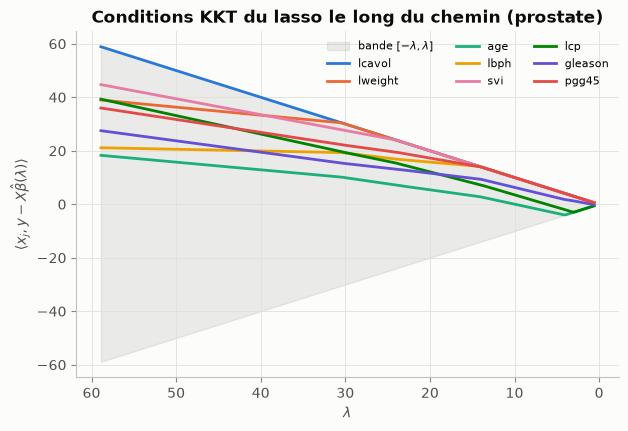

In [7]:
fig, ax = plt.subplots()
ax.fill_between(lam_grid, -lam_grid, lam_grid, color=GRAY, alpha=0.15, label=r"bande $[-\lambda, \lambda]$")
for j in range(8):
    ax.plot(lam_grid, inner[j], color=COLORS[j], label=pnames[j])
ax.set_xlabel(r"$\lambda$")
ax.set_ylabel(r"$\langle x_j, y - X\hat\beta(\lambda)\rangle$")
ax.set_title("Conditions KKT du lasso le long du chemin (prostate)")
ax.invert_xaxis()
ax.legend(ncol=3, fontsize=8)
plt.show()

Linéarité par morceaux : la formule (3.90) avec $\gamma_0=(\mathbf X_{\mathcal B}^T\mathbf X_{\mathcal B})^{-1}\mathbf s_{\mathcal B}$,
appliquée entre deux nœuds consécutifs, reproduit exactement les solutions de la descente de
coordonnées.

In [8]:
knots = path_p["lambdas"]
err = 0.0
for i, lam in enumerate(lam_grid):
    k = max(np.searchsorted(-knots, -lam), 1)    # segment [knots[k], knots[k-1]] contenant lambda
    lam0 = knots[k - 1]
    b0 = path_p["coefs"][:, k - 1]
    mid = (path_p["coefs"][:, k - 1] + path_p["coefs"][:, k]) / 2
    Bset = np.flatnonzero(mid != 0)              # variables actives sur le segment
    s = np.sign(Xp[:, Bset].T @ (yp - Xp @ b0))
    gamma0 = np.zeros(8)
    gamma0[Bset] = np.linalg.solve(Xp[:, Bset].T @ Xp[:, Bset], s)
    err = max(err, np.abs(b0 - (lam - lam0) * gamma0 - B_grid[:, i]).max())
print("écart max entre (3.90) et la descente de coordonnées :", err)

écart max entre (3.90) et la descente de coordonnées : 1.273911531818328e-11


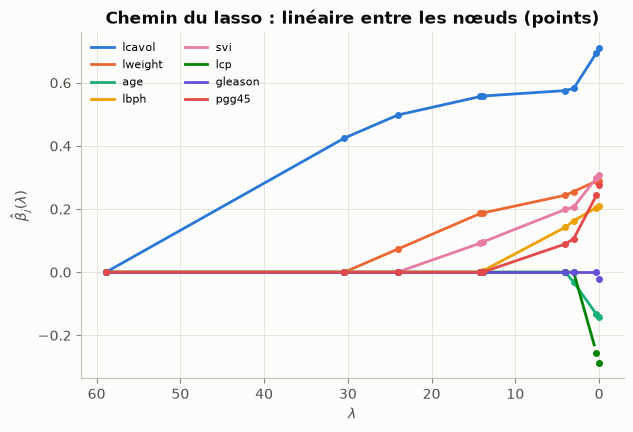

In [9]:
fig, ax = plt.subplots()
for j in range(8):
    ax.plot(lam_grid, B_grid[j], color=COLORS[j], label=pnames[j])
    ax.plot(knots, path_p["coefs"][j], "o", color=COLORS[j], ms=4)
ax.set_xlabel(r"$\lambda$")
ax.set_ylabel(r"$\hat\beta_j(\lambda)$")
ax.set_title("Chemin du lasso : linéaire entre les nœuds (points)")
ax.invert_xaxis()
ax.legend(ncol=2, fontsize=8)
plt.show()

> **À retenir.** Les conditions KKT du lasso disent que les variables actives ont un produit
> scalaire avec le résidu égal à $\pm\lambda$ (signe du coefficient), et les inactives un
> produit scalaire de valeur absolue $\le\lambda$. Tant que l'ensemble actif ne change pas,
> ces équations sont linéaires en $\lambda$ : le chemin est **linéaire par morceaux**.

## Exercice 3.28 : Lasso avec une variable dupliquée

**Énoncé (reformulé).** Pour une valeur donnée de $t$ dans la forme contrainte (3.51) du
lasso (minimiser la RSS sous $\sum_j|\beta_j|\le t$), le coefficient ajusté de $X_j$ vaut
$\hat\beta_j=a$. On ajoute une copie exacte $X_j^*=X_j$. Décrire l'ensemble des solutions
$(\hat\beta_j,\hat\beta_j^*)$ avec le même $t$.

### Solution

Notons $P(t)$ le problème initial et $P^*(t)$ le problème augmenté, en variables
$(\beta,\beta^*)$ ($\beta^*$ = coefficient de la copie) :
$\mathrm{RSS}^*(\beta,\beta^*)=\|\mathbf y-\sum_{k\ne j}\mathbf x_k\beta_k-\mathbf x_j(\beta_j+\beta^*)\|^2$
sous $\sum_{k\ne j}|\beta_k|+|\beta_j|+|\beta^*|\le t$.

1. **Fusion.** À $(\beta,\beta^*)$ associons $\tilde\beta$ égal à $\beta$ sauf $\tilde\beta_j=\beta_j+\beta^*$.
   Alors $\mathrm{RSS}^*(\beta,\beta^*)=\mathrm{RSS}(\tilde\beta)$ et, par l'inégalité triangulaire
   $|\beta_j+\beta^*|\le|\beta_j|+|\beta^*|$, $\tilde\beta$ est admissible pour $P(t)$. Donc
   $\min P^*\ge\min P$.
2. **Plongement.** $(\beta,0)$ est admissible pour $P^*(t)$ avec la même RSS : $\min P^*\le\min P$.
3. Les deux minimums sont **égaux**, et $(\beta,\beta^*)$ résout $P^*(t)$ si et seulement si
   il est admissible et $\tilde\beta$ résout $P(t)$.

Supposons la solution $\hat\beta$ de $P(t)$ unique (cas générique). Les solutions de $P^*(t)$ sont
alors exactement

$$
\beta_k=\hat\beta_k\ (k\ne j),\qquad \beta_j+\beta^*=a,\qquad |\beta_j|+|\beta^*|\le t-\textstyle\sum_{k\ne j}|\hat\beta_k| .
$$

- **Contrainte saturée** ($\|\hat\beta\|_1=t$, le cas intéressant, dès que $t$ est inférieur à
  la norme $\ell_1$ des moindres carrés) : le membre de droite vaut $|a|$, donc
  $|\beta_j|+|\beta^*|\le|a|=|\beta_j+\beta^*|$. L'inégalité triangulaire est une égalité, ce qui
  impose que $\beta_j$ et $\beta^*$ soient **de même signe** (que $a$). L'ensemble des solutions
  est le **segment**
  $$\{(\beta_j,\beta^*)=(\theta a,(1-\theta)a):\theta\in[0,1]\}.$$
- **Contrainte non saturée** (moindres carrés atteints) : l'ensemble est plus grand et contient
  des couples de signes opposés.

L'effet de la colinéarité exacte : **la solution n'est plus unique**. Le lasso sait que le
total vaut $a$ mais est indifférent à sa répartition entre les deux copies (toute répartition
de même signe coûte la même norme $\ell_1$).

### Vérification numérique

On duplique `lcavol` dans les données de la prostate et on résout le lasso augmenté
(forme lagrangienne, équivalente) par descente de coordonnées depuis plusieurs points de
départ : chaque départ aboutit à un point différent du segment, avec la même valeur du
critère.

In [10]:
lam = 10.0
b_orig = rc.lasso_cd(Xp, yp, lam)
a = b_orig[0]
X_dup = np.column_stack([Xp, Xp[:, 0]])
print(f"lasso initial : beta_lcavol = a = {a:.4f}")


def lasso_obj(X, y, b, lam):
    return 0.5 * np.sum((y - X @ b) ** 2) + lam * np.abs(b).sum()


sols = []
for start in np.linspace(-0.5, 1.5, 9):
    b0 = np.r_[b_orig, 0.0]
    b0[0], b0[8] = start * a, (1 - start) * a
    b = rc.lasso_cd(X_dup, yp, lam, beta0=b0)
    sols.append(b)
    print(f"départ ({b0[0]:+.3f}, {b0[8]:+.3f}) -> (beta_j, beta_j*) = ({b[0]:.4f}, {b[8]:.4f}),"
          f" somme = {b[0] + b[8]:.4f}, critère = {lasso_obj(X_dup, yp, b, lam):.6f}")
sols = np.array(sols)

lasso initial : beta_lcavol = a = 0.5649
départ (-0.282, +0.847) -> (beta_j, beta_j*) = (0.0000, 0.5649), somme = 0.5649, critère = 28.137837
départ (-0.141, +0.706) -> (beta_j, beta_j*) = (0.0000, 0.5649), somme = 0.5649, critère = 28.137837
départ (+0.000, +0.565) -> (beta_j, beta_j*) = (0.0000, 0.5649), somme = 0.5649, critère = 28.137837
départ (+0.141, +0.424) -> (beta_j, beta_j*) = (0.1412, 0.4236), somme = 0.5649, critère = 28.137837
départ (+0.282, +0.282) -> (beta_j, beta_j*) = (0.2824, 0.2824), somme = 0.5649, critère = 28.137837
départ (+0.424, +0.141) -> (beta_j, beta_j*) = (0.4236, 0.1412), somme = 0.5649, critère = 28.137837
départ (+0.565, +0.000) -> (beta_j, beta_j*) = (0.5649, 0.0000), somme = 0.5649, critère = 28.137837
départ (+0.706, -0.141) -> (beta_j, beta_j*) = (0.5649, 0.0000), somme = 0.5649, critère = 28.137837
départ (+0.847, -0.282) -> (beta_j, beta_j*) = (0.5649, -0.0000), somme = 0.5649, critère = 28.137837


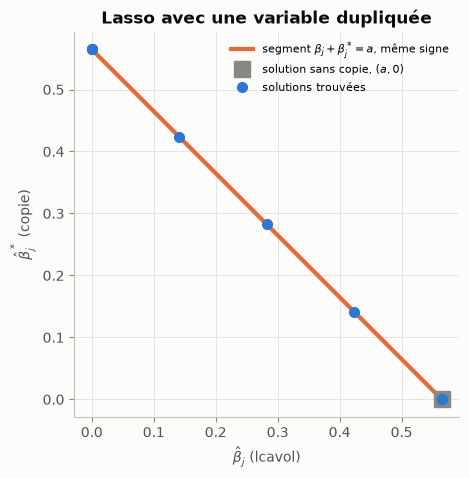

In [11]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, a], [a, 0], color=ORANGE, lw=3, label=r"segment $\beta_j+\beta_j^*=a$, même signe")
ax.plot(a, 0, "s", color=GRAY, ms=12, label=r"solution sans copie, $(a, 0)$")
ax.plot(sols[:, 0], sols[:, 8], "o", color=BLUE, ms=7, label="solutions trouvées")
ax.set_xlabel(r"$\hat\beta_j$ (lcavol)")
ax.set_ylabel(r"$\hat\beta_j^*$ (copie)")
ax.set_title("Lasso avec une variable dupliquée")
ax.set_aspect("equal")
ax.legend(fontsize=8)
plt.show()

> **À retenir.** Avec une copie exacte d'une variable, le lasso conserve la même solution
> « fusionnée » ($\beta_j+\beta_j^*=a$) mais la répartition entre les copies est **arbitraire**
> (tout le segment entre $(a,0)$ et $(0,a)$) : le lasso n'est pas strictement convexe et ne
> sait pas départager des variables identiques. Le résultat dépend de l'algorithme.

## Exercice 3.29 : Ridge avec une variable dupliquée

**Énoncé (reformulé).** Une régression ridge de paramètre $\lambda$ sur une seule variable
$X$ donne le coefficient $a$. On ajoute une copie exacte $X^*=X$ et on réajuste. Montrer que
les deux coefficients sont égaux et calculer leur valeur. Montrer plus généralement que si
l'on inclut $m$ copies d'une variable $X_j$ dans une régression ridge, leurs coefficients
sont tous égaux.

### Une seule variable

Avec $\mathbf x$ centré, la ridge minimise $\|\mathbf y-\mathbf xb\|^2+\lambda b^2$ ; en dérivant :
$-2\mathbf x^T(\mathbf y-\mathbf xb)+2\lambda b=0$, donc

$$
a=\frac{\mathbf x^T\mathbf y}{\mathbf x^T\mathbf x+\lambda}.
$$

### Deux copies : les coefficients sont égaux

On minimise $G(b_1,b_2)=\|\mathbf y-\mathbf x(b_1+b_2)\|^2+\lambda(b_1^2+b_2^2)$.

- **Unicité.** $G$ est somme d'une fonction convexe et de $\lambda(b_1^2+b_2^2)$, strictement
  convexe pour $\lambda>0$ : $G$ est strictement convexe et coercive, son minimiseur est unique.
- **Symétrie.** $G(b_1,b_2)=G(b_2,b_1)$. Si $(\hat b_1,\hat b_2)$ minimise $G$, alors
  $(\hat b_2,\hat b_1)$ aussi ; par unicité, $\hat b_1=\hat b_2=:b$.

Il reste à minimiser $g(b)=\|\mathbf y-2b\mathbf x\|^2+2\lambda b^2$ :
$g'(b)=-4\mathbf x^T(\mathbf y-2b\mathbf x)+4\lambda b=0$, d'où

$$
\hat b_1=\hat b_2=\frac{\mathbf x^T\mathbf y}{2\,\mathbf x^T\mathbf x+\lambda}.
$$

> **Intuition.** Pour une somme $b_1+b_2=c$ fixée (donc un ajustement fixé), la pénalité
> $b_1^2+b_2^2$ est minimale pour $b_1=b_2=c/2$ : la ridge **partage équitablement**.

### $m$ copies, en présence d'autres variables

Soit $F(\beta)=\|\mathbf y-\mathbf X\beta\|^2+\lambda\|\beta\|^2$ où $\mathbf X$ contient $m$ colonnes
identiques (indices $j_1,\dots,j_m$) et d'autres variables. Pour toute permutation $\sigma$ des
indices $j_1..j_m$, notons $\beta^\sigma$ le vecteur dont on a permuté ces coordonnées :
$\mathbf X\beta^\sigma=\mathbf X\beta$ (colonnes identiques) et $\|\beta^\sigma\|=\|\beta\|$, donc
$F(\beta^\sigma)=F(\beta)$. $F$ étant strictement convexe ($\lambda>0$), son minimiseur
$\hat\beta$ est unique, donc $\hat\beta^\sigma=\hat\beta$ pour toute $\sigma$ : les $m$
coefficients sont **égaux**.

Dans le cas d'une seule variable répétée $m$ fois, le même calcul donne

$$
\hat b=\frac{\mathbf x^T\mathbf y}{m\,\mathbf x^T\mathbf x+\lambda},
\qquad
m\hat b=\frac{\mathbf x^T\mathbf y}{\mathbf x^T\mathbf x+\lambda/m} :
$$

l'effet total est celui d'une ridge sur la variable seule avec une pénalité **divisée par $m$**.

### Vérification numérique

On répète `lcavol` $m$ fois dans les données de la prostate (avec les autres variables) et on
ajuste la ridge.

In [12]:
lam = 5.0
for m in (1, 2, 3, 5):
    Xm = np.column_stack([Xp] + [Xp[:, [0]]] * (m - 1))
    b = rc.ridge(Xm, yp, lam)
    copies = np.r_[b[0], b[8:]]
    print(f"m = {m} : coefficients des copies = {np.round(copies, 4)}, somme = {copies.sum():.4f}")

m = 1 : coefficients des copies = [0.6061], somme = 0.6061
m = 2 : coefficients des copies = [0.326 0.326], somme = 0.6519
m = 3 : coefficients des copies = [0.2229 0.2229 0.2229], somme = 0.6688
m = 5 : coefficients des copies = [0.1366 0.1366 0.1366 0.1366 0.1366], somme = 0.6829


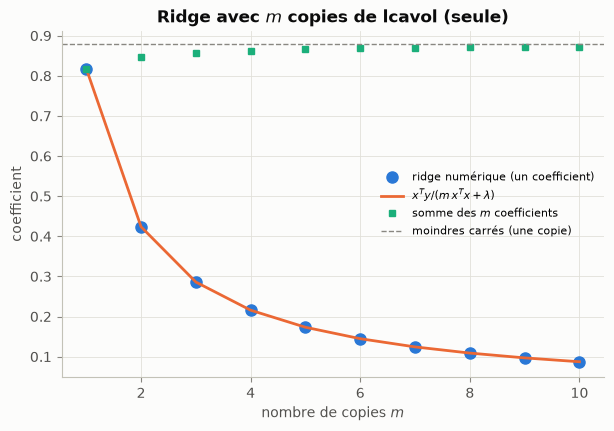

In [13]:
x = Xp[:, 0]
ms = np.arange(1, 11)
emp = [rc.ridge(np.column_stack([x] * m), yp, lam)[0] for m in ms]
fig, ax = plt.subplots()
ax.plot(ms, emp, "o", color=BLUE, ms=8, label="ridge numérique (un coefficient)")
ax.plot(ms, (x @ yp) / (ms * (x @ x) + lam), color=ORANGE, label=r"$x^Ty/(m\,x^Tx+\lambda)$")
ax.plot(ms, ms * np.array(emp), "s", color=COLORS[2], label=r"somme des $m$ coefficients")
ax.axhline((x @ yp) / (x @ x), color=GRAY, ls="--", lw=1, label="moindres carrés (une copie)")
ax.set_xlabel("nombre de copies $m$")
ax.set_ylabel("coefficient")
ax.set_title("Ridge avec $m$ copies de lcavol (seule)")
ax.legend(fontsize=8)
plt.show()

> **À retenir.** La pénalité ridge est strictement convexe et symétrique : des variables
> identiques reçoivent des coefficients **identiques**, et l'effet total
> $m\hat b$ correspond à une pénalité $\lambda/m$. C'est l'opposé du lasso (exercice 3.28),
> indifférent à la répartition.

## Exercice 3.30 : L'elastic net comme un lasso augmenté

**Énoncé (reformulé).** On considère le problème de l'elastic net

$$
\min_\beta\ \|\mathbf y-\mathbf X\beta\|^2+\lambda\big[\alpha\|\beta\|_2^2+(1-\alpha)\|\beta\|_1\big]
\qquad\text{(éq. (3.91))}.
$$

Montrer comment le transformer en un problème de lasso, en utilisant des versions augmentées
de $\mathbf X$ et $\mathbf y$.

### Solution

Posons

$$
\mathbf X^*=\begin{pmatrix}\mathbf X\\ \sqrt{\lambda\alpha}\,\mathbf I_p\end{pmatrix}\ \ ((N+p)\times p),
\qquad
\mathbf y^*=\begin{pmatrix}\mathbf y\\ \mathbf 0_p\end{pmatrix}.
$$

Le carré de la norme d'un vecteur « empilé » est la somme des carrés des normes des blocs :

$$
\|\mathbf y^*-\mathbf X^*\beta\|^2=\|\mathbf y-\mathbf X\beta\|^2+\|\mathbf 0-\sqrt{\lambda\alpha}\,\beta\|^2=\|\mathbf y-\mathbf X\beta\|^2+\lambda\alpha\|\beta\|_2^2 .
$$

Le critère (3.91) s'écrit donc

$$
\|\mathbf y^*-\mathbf X^*\beta\|^2+\lambda^*\|\beta\|_1,\qquad\lambda^*=\lambda(1-\alpha):
$$

c'est un **lasso** sur les données augmentées $(\mathbf X^*,\mathbf y^*)$, de paramètre
$\lambda(1-\alpha)$ (ou $\lambda(1-\alpha)/2$ dans la convention avec $\tfrac12$ devant la RSS).
Tout algorithme de lasso (LAR-lasso, descente de coordonnées) résout donc l'elastic net.

> **Remarques.**
> - Comme on ajoute $p$ « pseudo-observations » de réponse nulle, la partie ridge revient à
>   tirer les coefficients vers $0$ : c'est l'interprétation de la ridge comme régression sur
>   des données fictives.
> - $\mathbf X^*$ est toujours de rang $p$ (grâce au bloc $\sqrt{\lambda\alpha}\mathbf I$) : le
>   lasso augmenté est strictement convexe, a une solution unique et peut sélectionner jusqu'à
>   $p$ variables même si $p>N$ (le lasso ordinaire s'arrête à $N$).
> - Si les colonnes de $\mathbf X$ sont centrées, celles de $\mathbf X^*$ ne le sont plus ; on
>   centre donc $\mathbf X$ et $\mathbf y$ **avant** l'augmentation et on n'ajoute pas d'ordonnée
>   à l'origine au lasso augmenté.

### Vérification numérique

Sur la prostate, on résout le lasso augmenté par notre descente de coordonnées, puis on
compare à l'implémentation `ElasticNet` de scikit-learn (contrôle uniquement ; il faut
traduire ses paramètres : elle minimise
$\frac1{2N}\|\mathbf y-\mathbf X\beta\|^2+a\,\rho\|\beta\|_1+\frac a2(1-\rho)\|\beta\|_2^2$).

In [14]:
from sklearn.linear_model import ElasticNet

lam, alpha = 20.0, 0.5
N = len(yp)
Xa, ya, lam1 = rc.elastic_net_augment(Xp, yp, lam, alpha)
b_aug = rc.lasso_cd(Xa, ya, lam1 / 2)            # convention 1/2 RSS + (lam1/2) ||b||_1
a_sk = lam * (1 - alpha) / (2 * N) + lam * alpha / N
rho = lam * (1 - alpha) / (2 * N) / a_sk
b_sk = ElasticNet(alpha=a_sk, l1_ratio=rho, fit_intercept=False, tol=1e-12, max_iter=100000).fit(Xp, yp).coef_
print("lasso augmenté :", b_aug)
print("ElasticNet     :", b_sk)
print("critère (3.91) :", rc.elastic_net_objective(Xp, yp, b_aug, lam, alpha),
      " /", rc.elastic_net_objective(Xp, yp, b_sk, lam, alpha))

lasso augmenté : [0.4866 0.2293 0.     0.1224 0.2008 0.     0.     0.1022]
ElasticNet     : [ 0.4866  0.2293 -0.      0.1224  0.2008  0.      0.      0.1022]
critère (3.91) : 49.15496091833909  / 49.154960918339086


Effet de groupe : on construit trois prédicteurs presque identiques (corrélation $\approx0{,}99$)
et trois prédicteurs de bruit. Le long du chemin, le lasso fait entrer les variables du
groupe **une par une**, avec des coefficients très inégaux (le troisième membre du groupe
finit même négatif), alors que l'elastic net (via le lasso augmenté) les fait entrer
**ensemble** avec des coefficients presque égaux tant que la pénalité est forte - à
rapprocher des exercices 3.28 et 3.29.

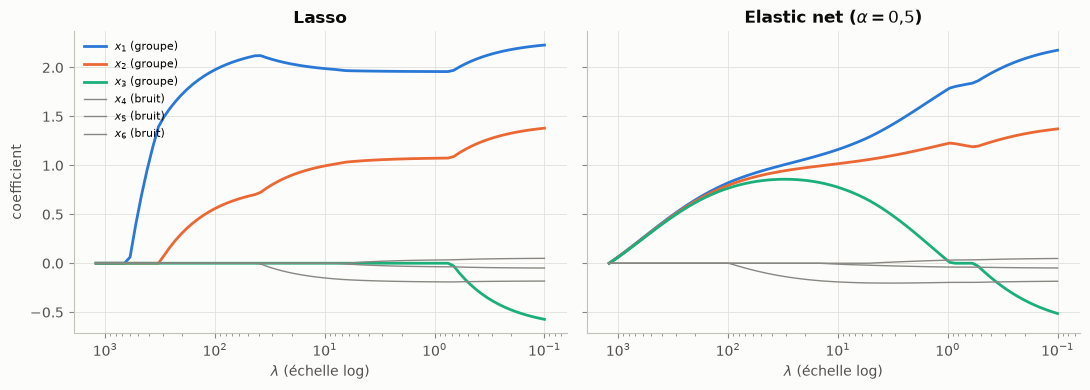

In [15]:
rng = np.random.RandomState(0)
N = 100
zg = rng.randn(N)
Xg = np.column_stack([zg + 0.1 * rng.randn(N) for _ in range(3)] + [rng.randn(N) for _ in range(3)])
Xg, _, _, _ = rc.standardize(Xg)
yg = 3 * zg + rng.randn(N)
yg -= yg.mean()
cmax = np.abs(Xg.T @ yg).max()
lams = np.logspace(np.log10(4 * cmax), -1, 80)   # au-delà de 4 cmax, tout est nul
path_lasso = np.column_stack([rc.lasso_cd(Xg, yg, l / 2) for l in lams])
path_enet = []
for l in lams:
    Xa_g, ya_g, l1 = rc.elastic_net_augment(Xg, yg, l, 0.5)
    path_enet.append(rc.lasso_cd(Xa_g, ya_g, l1 / 2))
path_enet = np.column_stack(path_enet)
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, P, title in [(axes[0], path_lasso, "Lasso"), (axes[1], path_enet, r"Elastic net ($\alpha = 0{,}5$)")]:
    for j in range(6):
        ax.plot(lams, P[j], color=COLORS[j] if j < 3 else GRAY, lw=2 if j < 3 else 1,
                label=fr"$x_{j + 1}$" + (" (groupe)" if j < 3 else " (bruit)"))
    ax.set_xscale("log")
    ax.set_xlabel(r"$\lambda$ (échelle log)")
    ax.set_title(title)
    ax.invert_xaxis()
axes[0].set_ylabel("coefficient")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

> **À retenir.** L'elastic net n'est rien d'autre qu'un **lasso sur données augmentées** :
> $\mathbf X^*=[\mathbf X;\sqrt{\lambda\alpha}\,\mathbf I]$, $\mathbf y^*=[\mathbf y;\mathbf 0]$,
> pénalité $\ell_1$ de poids $\lambda(1-\alpha)$. La partie quadratique rend le problème
> strictement convexe et fait entrer **ensemble** les variables corrélées.